Multiple Linear Regression

-As seen in simple Linear Regression, we used single independent variable for car price prediction.

-However, in real world datasets, for accurate prediction of car price, we neet to consider multiple reatures/variables instead of single one.
In such scenario multiple linear regression would be helpful

Predict car price using variables [horsepower, curb-wiught, engine-size, highway-mpg]

In [1]:
import os #using another server
import pandas as pd  #analysis
import numpy as np #numerice analysis
import matplotlib.pyplot as plt #plot and visualize
import seaborn as sns #high user interface
from sklearn.linear_model import LinearRegression #for modeling sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import csv

In [2]:
data_path = 'automobileEDA.csv'
df = pd.read_csv(data_path)   #read csv path
df

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,9.5,114.0,5400.0,23,28,16845.0,10.217391,Medium,0,1
197,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,8.7,160.0,5300.0,19,25,19045.0,12.368421,High,0,1
198,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,8.8,134.0,5500.0,18,23,21485.0,13.055556,Medium,0,1
199,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,23.0,106.0,4800.0,26,27,22470.0,9.038462,Medium,1,0


In [3]:
X = df.drop('price', axis=1)   #independent features drop from column 1st
Y = df['price']  #dependent features

In [29]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=1)

In [7]:
to_select = ['horsepower', 'curb-weight','engine-size','highway-mpg']
X_train_mult = X_train[to_select].values
X_test_mult = X_test[to_select].values

In [24]:
multi_lm = LinearRegression()
multi_lm.fit(X_train_mult, Y_train)

LinearRegression()

In [25]:
y_hat_simple = multi_lm.predict(X_test_mult)

In [26]:
y_hat_simple[:5]

array([11457.56050541,  5966.17033563, 11313.13362185,  6839.1134896 ,
       15765.36249767])

In [27]:
multi_lm.intercept_

-11539.108515802094

In [28]:
multi_lm.coef_

array([ 54.23019834,   3.1154028 ,  93.34038826, -18.71070774])

Price = -11539.108515802094 + 54.23019834 * horsepower + 3.1154028 * curb-weight + 93.34038326 * engine size - 1871070774 * highway-mpg

Exercies:

-Fit Multiple Linear Regression with [engine-size, horsepower] as independent variable to predict car price

-Fit Multiple Linear Regression with [normalized-looses, highway-mpg] as independent variable to predict car price

Model Evaluation using Visualization

-Now we have to developed our simple Linear Regression and Multiple Linear Regression model.

-How do we evaluated them ?

-We can evaluate our Linear Regression either visually or numerically.

-Let's start evaluate our Linear Regression model visually using Regression Plot and Distribution Plot.

Regression Plot

<function matplotlib.pyplot.show(close=None, block=None)>

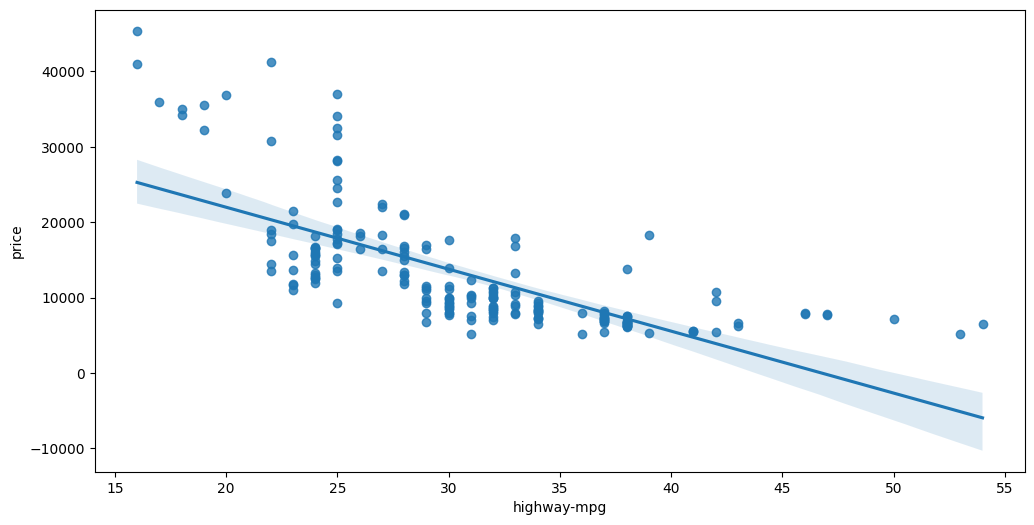

In [20]:
plt.figure(figsize=(12,6))
sns.regplot(x='highway-mpg',y='price',data=df)
plt.show

-We see slope of the line is negative, which we predicted earlier when fitting simple linear regression line.

-More dispersed is the data point from the regression line, it will be not suitable to model such data point with linear refression.

-Hence, if the data is too far from the line, this linear model might not be the best fit model for this data.

-In the above plot, data is not perfectly linear, so simple polynomial regression can do a better Job, since it can capture non linear data.

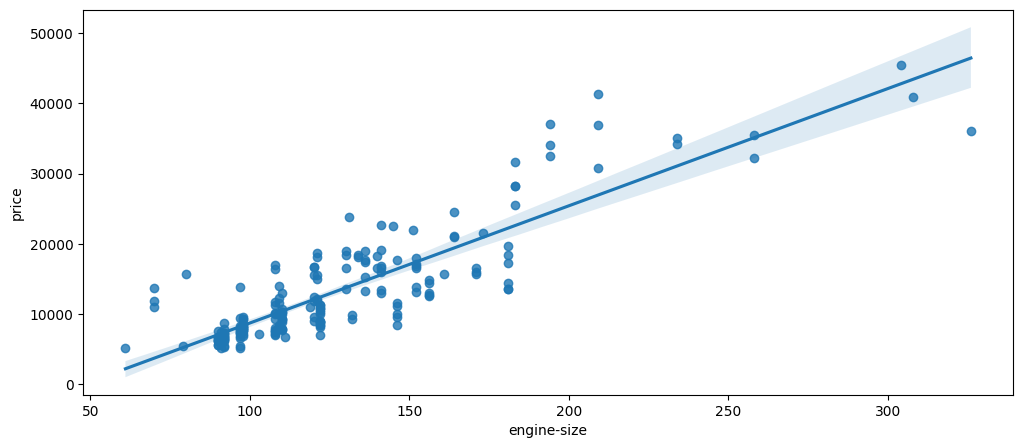

In [21]:
plt.figure(figsize=(12,5))
sns.regplot(x='engine-size',y='price', data=df)
plt.show()

This show that increase in engine size increase the price of the car i.e positive correlation

Distribution plot

-We successfully visualize linear regression model using Regression plot. It will be complicated for multiple linear 
regression since there will multiple independent variables, in such scenarios we could using Distribution plot.

-Now let's visualize our prediction from linear regression model using Distribution plot

In [31]:
X_train_simple = X_train['highway-mpg'].values.reshape(-1,1)
X_test_simple = X_test['highway-mpg'].values.reshape(-1,1)

In [32]:
simple_lm = LinearRegression()
simple_lm.fit(X_train_simple, Y_train)

LinearRegression()

In [33]:
y_hat_simple = simple_lm.predict(X_test_simple)

In [34]:
y_hat_simple[:5]

array([10530.19044542,  7150.17926639, 12220.19603494, 10530.19044542,
       13910.20162445])

C:\Users\arun\AppData\Local\Temp\ipykernel_15752\3901139243.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  axl = sns.distplot(Y_test, hist=False, color='r', label='Actual value')
C:\Users\arun\AppData\Local\Temp\ipykernel_15752\3901139243.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.dist

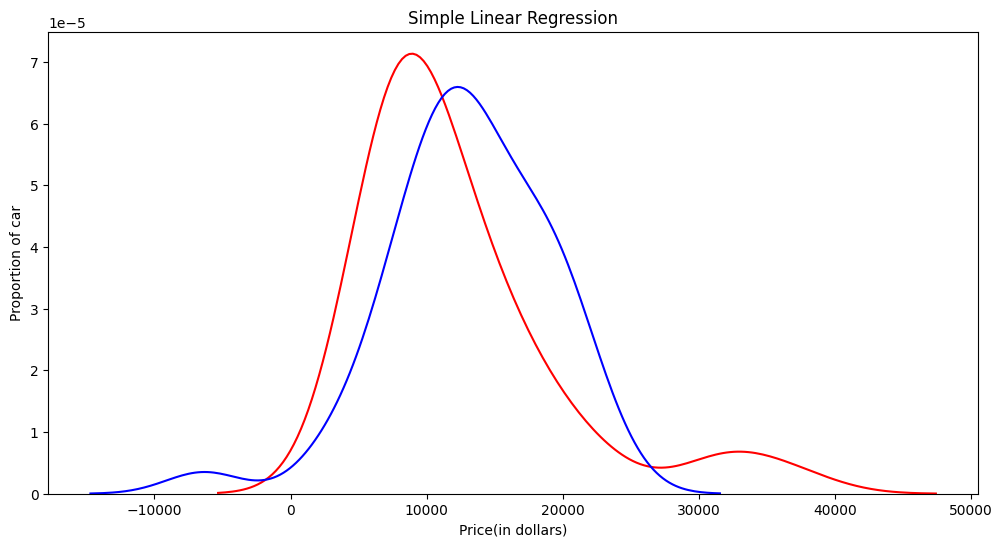

In [40]:
plt.figure(figsize=(12,6))
axl = sns.distplot(Y_test, hist=False, color='r', label='Actual value')
sns.distplot(y_hat_simple, hist=False, color='b', label='Fitted value', ax=axl)
plt.title('Simple Linear Regression')
plt.xlabel('Price(in dollars)')
plt.ylabel('Proportion of car')
plt.show()
plt.close()